# Assignment 08 — Hussein Jawad
**E89 Deep Learning · RNNs and LSTMs for time series** (based on Lecture 8 and Géron, *Hands-On ML*, Ch. 14)

---

# Problem 1: Predicting Microsoft (MSFT) opening prices with an RNN and an LSTM
Use the class notebooks `1_RNN_apple_stock_prediction` and `2_LSTM_apple_stock_prediction` with a company other than Apple:
train on its stock prices from January 2016 to September 6, 2026, then predict its opening prices from September 9 to October 10, 2026.

I ran this notebook on Google Colab with a T4 GPU (PyTorch).

**Contents**
1. Approach
2. Solution: Part A (RNN) and Part B (LSTM)
3. Results and discussion
4. Appendix: How RNNs and LSTMs work

# 1. Approach

### Goal
Train a recurrent neural network on the daily opening prices of a company other than Apple, and use it to "predict" the opening
price for each trading day of a later period that the network has not seen.

### Company and data
I chose Microsoft (ticker `MSFT`). It has been listed since 1986, so the full history from January 2016 is available.
I downloaded the prices from Yahoo Finance with the `yfinance` library.

| Data set | Requested period | Trading days in the data | Purpose |
|---|---|---|---|
| Training | Jan 1, 2016 to Sep 6, 2026 | 2,684 (Jan 4, 2016 – Sep 4, 2026) | The network learns from these prices |
| Test | Sep 9, 2026 to Oct 10, 2026 | 23 (Sep 9 – Oct 9, 2026) | Not used in training; only for checking the predictions |

Sep 6, 2026 is a Sunday and Oct 10, 2026 is a Saturday, so the last trading days in the two sets are Friday Sep 4 and Friday Oct 9.
The market was closed on Monday Sep 7 (Labor Day), and Tuesday Sep 8 is left out as the assignment specifies.

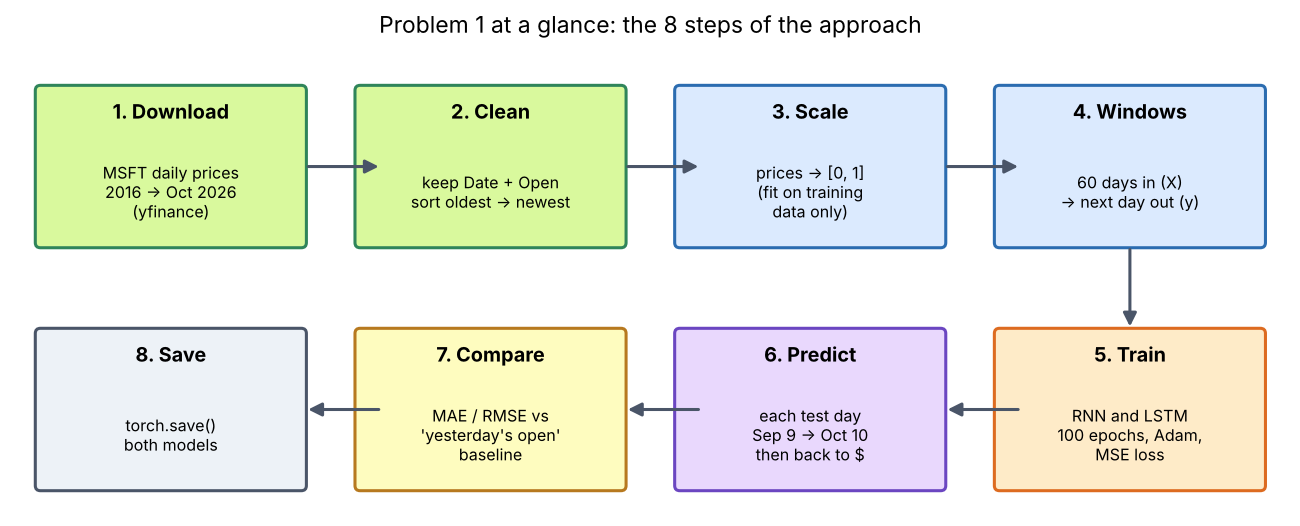

### Steps
1. Download and clean the data. I keep only the date and the opening price, sorted from oldest to newest.
2. Scale the prices to 0–1 (the lowest training price becomes 0 and the highest becomes 1), since neural networks train better on
   small numbers. The scaler gets its min and max from the training data only, so nothing from the test period leaks into training.
3. Make training examples with a sliding window. Each example is 60 consecutive trading days (about 3 months) as the input and the
   next day's opening price as the target. Moving the window forward one day at a time gives 2,624 examples (see Appendix 4.5).
4. Build the models from class: 4 stacked recurrent layers with 50 units each, dropout of 0.2 after each layer (randomly turning off
   20% of the units during training to reduce overfitting), and a linear layer that outputs the predicted price. Part A uses the vanilla
   RNN from class notebook 1 and Part B the LSTM from class notebook 2.
5. Train each model for 100 epochs with the Adam optimizer and mean squared error (MSE) loss, using the training loop from its class
   notebook (the RNN notebook clips the gradients to keep training stable; the LSTM notebook does not).
6. Predict the test period one day at a time (rolling one-step-ahead). For each test day the model gets the 60 actual prices before
   that day and predicts that day only. It does not forecast the whole month from September 4.

   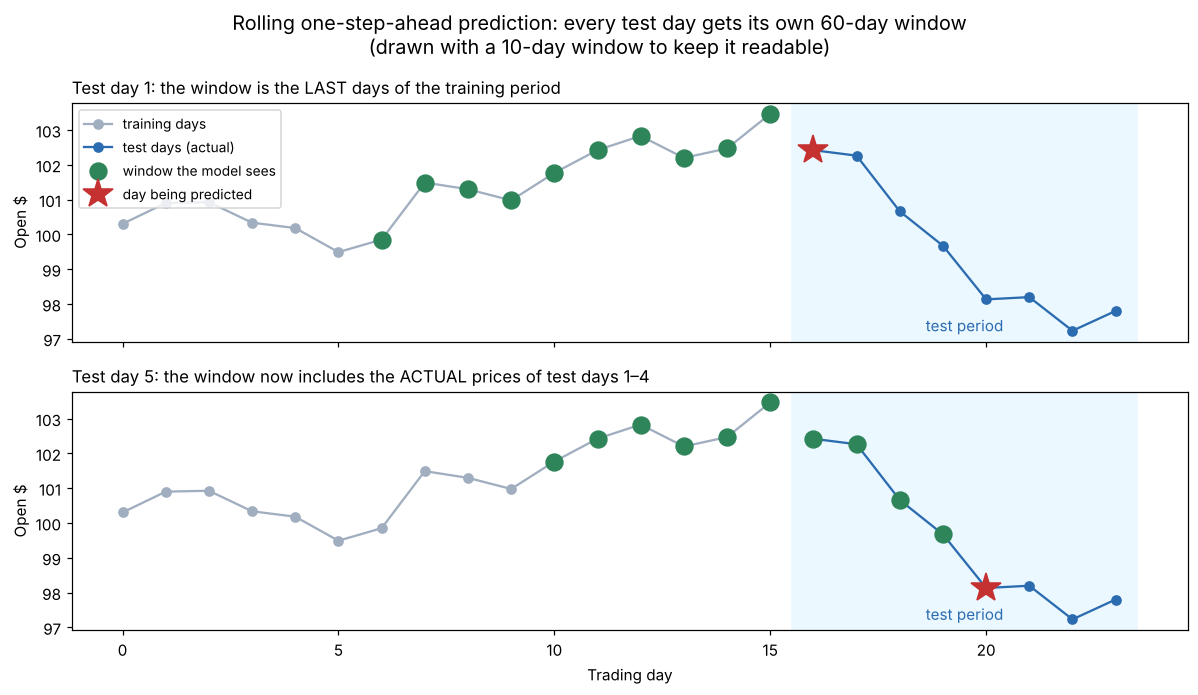
7. Convert the predictions back to dollars and compare them with a baseline.
   * MAE (mean absolute error) is the average miss in dollars. For example, an MAE of \$3 means the prediction is off by about \$3 on a typical day.
   * RMSE (root mean squared error) is similar, but large misses count more.
   * The baseline is the simplest rule: tomorrow's open = today's open.
8. Save both models with `torch.save` (the PyTorch equivalent of Keras' `model.save('...')`, which the assignment asks for).

### Code
I ran the code from the two class notebooks. Part A is `1_RNN_apple_stock_prediction` and Part B is `2_LSTM_apple_stock_prediction`.
The only changes are:
* a cell that downloads the MSFT prices and saves them as `MSFT.csv` and `MSFT_test.csv` (in place of `AAPL.csv` and `AAPL_test.csv`),
* the CSV file names, and "Apple" renamed to "MSFT" in variable names, chart titles and saved file names,
* new comments.

Steps 1–4 (loading, scaling, windows and mini-batches) are the same code in both class notebooks, so Part B reuses the data from Part A
instead of running them again. Part B first re-seeds the random generators and rebuilds the mini-batches (the same lines as Steps 1
and 4), so the LSTM starts exactly as it would in its own notebook.


# 2. Solution

## Part A: RNN (class notebook `1_RNN_apple_stock_prediction`)

### Step 0: Install yfinance
Colab already has PyTorch, NumPy, pandas, matplotlib and scikit-learn; `yfinance` is needed to download the prices.

In [1]:
# Installs yfinance, the library that downloads stock prices from Yahoo Finance.
# Colab already has everything else (PyTorch, NumPy, pandas, matplotlib, scikit-learn).
# -q hides the installation log; -U updates yfinance if an older version is installed.
%pip install -q -U yfinance

### Step 1: Libraries, settings and device
The hyperparameters are the ones from class: a 60-day window, 4 layers of 50 units, dropout 0.2, batch size 32, 100 epochs,
learning rate 0.001 and gradient clipping at 1.0. The device is the hardware that runs the calculations; in Colab it should print `cuda` (the GPU).

In [2]:
# STEP 1: load the libraries, set the hyperparameters (the settings chosen by hand before
# training), make the randomness repeatable, and choose the hardware to run on.
# Result: all settings below, plus `device` ("cuda" in Colab with a GPU).

from pathlib import Path          # Builds file paths, e.g. Path("data") / "MSFT.csv".
import random                     # Python's random-number generator.
import numpy as np                # Fast arrays of numbers; used to cut the price windows.
import pandas as pd               # Tables (rows and columns); used to read the CSV files.
import matplotlib.pyplot as plt   # Draws the charts.
from sklearn.preprocessing import MinMaxScaler  # Rescales prices to the range 0-1.
import torch                      # PyTorch, the deep-learning library.
from torch import nn              # Ready-made layers (RNN, LSTM, Linear, Dropout) and losses.
# TensorDataset pairs each input window with its answer; DataLoader hands them out in batches.
from torch.utils.data import TensorDataset, DataLoader

DATA_DIR = Path.cwd()/"data"  # Folder for MSFT.csv and MSFT_test.csv.
OUTPUT_DIR = Path.cwd()/"output"  # Folder for the saved models.
LOOKBACK = 60          # Each prediction looks at the previous 60 trading days (~3 months).
HIDDEN_SIZE = 50       # Size of the memory: each layer keeps 50 numbers per day.
DROPOUT = 0.2          # During training, hide 20% of values at random (prevents memorising).
BATCH_SIZE = 32        # The weights are updated after every group ("batch") of 32 windows.
EPOCHS = 100           # One epoch = one pass over all training windows; we do 100 passes.
LEARNING_RATE = 0.001  # How big each weight update is; small = slow but stable learning.
MAX_GRAD_NORM = 1.0  # Upper limit on the size of each update (explained in Step 6).
SEED = 42              # Starting point for all random numbers, so every run starts the same.

# Neural networks use random numbers (starting weights, shuffling, dropout).
# Fixing the seed of every generator makes a re-run start from the same random numbers.
# (A GPU can still give tiny differences from run to run.)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():         # Only if an NVIDIA GPU is present:
    torch.cuda.manual_seed_all(SEED)  # seed the GPU's generator as well.

# Pick the fastest hardware available. "cuda" = NVIDIA GPU (what Colab provides),
# "mps" = the GPU in Apple-silicon Macs, otherwise the normal processor ("cpu").
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"PyTorch {torch.__version__}; device: {device}")  # In Colab this should say cuda.
# If the Apple GPU (mps) cannot run an operation, set device = torch.device("cpu") instead.

PyTorch 2.11.0+cu130; device: cuda


### Step 2: Download, load and clean the data
The first cell downloads the MSFT prices into `data/MSFT.csv` (Jan 1, 2016 to Sep 6, 2026) and `data/MSFT_test.csv` (Sep 9 to Oct 10, 2026).
The `end` date in `yfinance` is not included, so one day is added to it. The second cell is the class code: it reads the two files, keeps
`Date` and `Open`, removes bad rows, sorts by date and checks that all training dates come before the test dates.

In [3]:
# Downloads Microsoft's daily prices and saves them as CSV files in DATA_DIR, in the same
# format as AAPL.csv / AAPL_test.csv from class, so the class code below can read them.
# Result: data/MSFT.csv (training period) and data/MSFT_test.csv (test period).
import yfinance as yf


def download_to_csv(start, end, filename):
    # yfinance stops the day BEFORE `end`, so add one day to include the last requested day.
    end_exclusive = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    # One row per trading day with Open, High, Low, Close, ... prices.
    # auto_adjust=False keeps the real opening price as it was quoted that day.
    frame = yf.download("MSFT", start=start, end=end_exclusive, auto_adjust=False,
                        progress=False)
    # Newer yfinance versions use two-level column names such as ("Open", "MSFT")
    # (pandas calls this a MultiIndex); keep only the first part, e.g. "Open".
    if isinstance(frame.columns, pd.MultiIndex):
        frame.columns = frame.columns.get_level_values(0)
    frame = frame.reset_index()  # The dates are the row labels; turn them into a Date column.
    DATA_DIR.mkdir(parents=True, exist_ok=True)     # Create the data folder if it is missing.
    frame.to_csv(DATA_DIR / filename, index=False)  # Save the table as a CSV file.
    print(f"Saved {len(frame)} rows to {DATA_DIR / filename}")


download_to_csv("2016-01-01", "2026-09-06", "MSFT.csv")       # Training period (assignment).
download_to_csv("2026-09-09", "2026-10-10", "MSFT_test.csv")  # Test period (assignment).

Saved 2684 rows to /content/data/MSFT.csv
Saved 23 rows to /content/data/MSFT_test.csv


In [4]:
# STEP 2: read the two CSV files, keep only Date and Open, remove bad rows, sort by date,
# and check that the whole training period comes before the test period.
# Result: msft_train and msft_test, two tables with columns Date and Open.

def find_csv(*names):
    # Returns the path of the first of the given file names that exists in DATA_DIR.
    data_dir = Path(DATA_DIR).expanduser()  # expanduser turns "~" into the home folder.
    for name in names:
        path = data_dir / name
        if path.is_file():
            return path
    # None of the files exist: stop and say where the file was expected.
    raise FileNotFoundError(
        f"Expected one of {names} in {data_dir.resolve()}. "
        "Copy the original CSV files there or change DATA_DIR."
    )


def load_prices(path):
    # Reads one CSV file and returns a clean table with just Date and Open.
    frame = pd.read_csv(path)
    frame.columns = frame.columns.str.strip()  # Remove spaces around column names.
    if not {"Date", "Open"}.issubset(frame.columns):  # Both columns must be present.
        raise ValueError(f"{path.name} must contain Date and Open columns.")
    frame = frame[["Date", "Open"]].copy()  # Only the opening price is used as input.
    # Turn the date text into real dates. Text that is not a date becomes NaT
    # ("not a time"), which is removed below.
    frame["Date"] = frame["Date"].map(lambda value: pd.to_datetime(value, errors="coerce"))
    # Turn the price text into numbers (removing commas such as "1,234.5"). Text that is
    # not a number becomes NaN ("not a number"), which is removed below.
    frame["Open"] = pd.to_numeric(
        frame["Open"].astype(str).str.replace(",", "", regex=False), errors="coerce"
    )
    frame = frame.dropna(subset=["Date", "Open"])  # Remove the rows with NaT or NaN.
    frame = frame.sort_values("Date").reset_index(drop=True)  # Oldest first, rows renumbered.
    # Safety checks: there must be prices left, none infinite, and no date twice.
    if frame.empty or not np.isfinite(frame["Open"].to_numpy()).all():
        raise ValueError(f"{path.name} contains no usable prices or contains infinite values.")
    if frame["Date"].duplicated().any():
        raise ValueError(f"{path.name} contains duplicate dates; resolve them before training.")
    return frame


msft_train = load_prices(find_csv("MSFT.csv"))      # Jan 2016 - Sep 2026: used for training.
msft_test = load_prices(find_csv("MSFT_test.csv"))  # Sep 9 - Oct 10, 2026: used for testing.
# At least 61 training days are needed to build one 60-day window plus its answer.
if len(msft_train) <= LOOKBACK:
    raise ValueError(f"Training data needs more than {LOOKBACK} observations.")
# The model must never train on days from the test period.
if msft_train["Date"].max() >= msft_test["Date"].min():
    raise ValueError("All training dates must precede all test dates.")
print(f"Training rows: {len(msft_train)}; test rows: {len(msft_test)}")
print("Training dates:", msft_train["Date"].min(), "to", msft_train["Date"].max())
print("Test dates:", msft_test["Date"].min(), "to", msft_test["Date"].max())
msft_train.head()  # Show the first 5 rows to check the data looks right.

Training rows: 2684; test rows: 23
Training dates: 2016-01-04 00:00:00 to 2026-09-04 00:00:00
Test dates: 2026-09-09 00:00:00 to 2026-10-09 00:00:00


,Date,Open
0,2016-01-04,54.320000
1,2016-01-05,54.930000
2,2016-01-06,54.320000
3,2016-01-07,52.700001
4,2016-01-08,52.369999


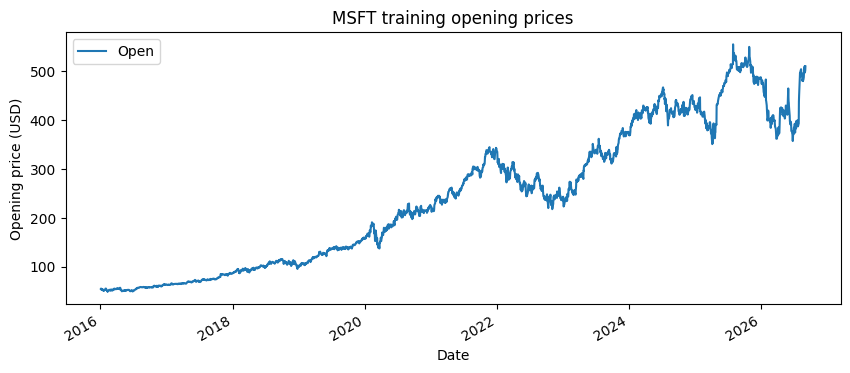

In [5]:
# Chart of the training prices, to see the overall trend and the price range.
msft_train.plot(x="Date", y="Open", figsize=(10, 4), title="MSFT training opening prices")
plt.ylabel("Opening price (USD)")
plt.show()

### Step 3: Scale the prices and build the training windows
The scaler is fitted on the training prices only and maps them to [0, 1]; test prices above the training maximum would get values above 1.
For each target day *i*, the input window is days *i − 60* to *i − 1*. With *N* training days this gives *N − 60* examples, each of shape `(60, 1)`.

In [6]:
# STEP 3: rescale the prices to 0-1 and cut the training data into 60-day windows.
# Result: features_set (the inputs) with shape (2624, 60, 1) and labels (the answers)
# with shape (2624, 1). Each input is 60 days of prices; its answer is the 61st day.

# Take the Open column as an array with one row per day and one column.
# float32 is the number format PyTorch uses for its weights.
msft_train_open = msft_train[["Open"]].to_numpy(dtype=np.float32)
msft_test_open = msft_test[["Open"]].to_numpy(dtype=np.float32)
# Scale with x_scaled = (x - min) / (max - min): the lowest training price becomes 0 and
# the highest becomes 1. fit_transform learns min and max from the TRAINING prices only,
# so the model learns nothing about the test period.
scaler = MinMaxScaler(feature_range=(0, 1))
msft_train_scaled = scaler.fit_transform(msft_train_open).astype(np.float32)

# For each answer day i (starting at day 60), take the 60 days just before it
# (days i-60 ... i-1) as the input window, and stack all windows into one array.
features_set = np.stack([
    msft_train_scaled[i - LOOKBACK:i]
    for i in range(LOOKBACK, len(msft_train_scaled))
])
# The answer for each window is the price of the day right after it.
labels = msft_train_scaled[LOOKBACK:].copy()
print("Inputs:", features_set.shape)  # (windows, 60 days, 1 price per day)
print("Targets:", labels.shape)       # (windows, 1 answer)

Inputs: (2624, 60, 1)
Targets: (2624, 1)


### Step 4: Mini-batches
`TensorDataset` pairs each window with its target and `DataLoader` serves them in shuffled mini-batches of 32. Shuffling whole windows
is fine, because the order of the days inside each window does not change.

In [7]:
# STEP 4: turn the arrays into PyTorch tensors and prepare them to be served in batches.
# A tensor is PyTorch's version of a NumPy array; it can be moved to the GPU.
# Result: train_loader, which gives 82 batches of up to 32 (window, answer) pairs per epoch.

X_train = torch.from_numpy(features_set).float()  # Inputs as a float32 tensor.
y_train = torch.from_numpy(labels).float()        # Answers as a float32 tensor.
train_dataset = TensorDataset(X_train, y_train)   # Keeps each window next to its answer.

# The DataLoader shuffles the windows each epoch (so the model doesn't see them in date
# order every time) and hands them out 32 at a time. Shuffling whole windows is fine: the
# order of the 60 days INSIDE each window never changes. The seeded generator makes the
# shuffle order the same in every run.
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    num_workers=0,  # Prepare batches in the notebook itself (no helper processes needed).
)
print(f"{len(train_dataset)} examples in {len(train_loader)} batches per epoch")

2624 examples in 82 batches per epoch


### Step 5: The RNN model
Each RNN layer updates its hidden state with $h_t = \tanh(W_{ih}x_t + b_{ih} + W_{hh}h_{t-1} + b_{hh})$, using the same weights at every
time step. The model has 4 RNN layers of 50 units with dropout after each; the output of the last layer at the last day (day 60) goes into
a linear layer that predicts the next day's price.

| Operation | Shape |
|---|---|
| Input batch | `(B, 60, 1)` |
| Output of each RNN layer | `(B, 60, 50)` |
| Last day of the 4th layer | `(B, 50)` |
| Linear output | `(B, 1)` |

In [8]:
# STEP 5: define the RNN model and create it.
# Data flows: 60 daily prices -> 4 stacked RNN layers -> the memory after day 60
# -> one Linear layer -> 1 number = the predicted (scaled) price for the next day.

class MsftRNN(nn.Module):
    # __init__ creates the layers (and their weights) once, when the model is built.
    def __init__(self, input_size=1, hidden_size=50, dropout=0.2):
        super().__init__()  # Required first line: lets PyTorch track the layers' weights.

        # An RNN layer reads the days one by one and updates a memory of 50 numbers each
        # day: new memory = tanh(weights x today's input + weights x yesterday's memory).
        # tanh keeps the memory between -1 and 1. batch_first=True means the data is
        # arranged as (windows in the batch, days, values per day).
        # Layer 1 reads 1 value per day (the price) ...
        self.rnn1 = nn.RNN(input_size, hidden_size, num_layers=1,
                           nonlinearity="tanh", batch_first=True)
        # ... and layers 2-4 each read the 50 memory values per day from the layer below,
        # which lets them pick up more complex patterns.
        self.rnn2 = nn.RNN(hidden_size, hidden_size, num_layers=1,
                           nonlinearity="tanh", batch_first=True)
        self.rnn3 = nn.RNN(hidden_size, hidden_size, num_layers=1,
                           nonlinearity="tanh", batch_first=True)
        self.rnn4 = nn.RNN(hidden_size, hidden_size, num_layers=1,
                           nonlinearity="tanh", batch_first=True)

        # Dropout after each layer: during training it hides 20% of the values at random,
        # so the model cannot rely on any single value (this reduces overfitting).
        # It is switched off automatically when making predictions.
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)
        self.dropout4 = nn.Dropout(dropout)
        # The output layer combines the 50 memory values into 1 predicted price.
        self.output = nn.Linear(hidden_size, 1)

    # forward describes how a batch of windows moves through the layers.
    # x arrives with shape (B, 60, 1): B windows, 60 days, 1 price per day.
    def forward(self, x):
        # Each RNN layer returns two things: its memory for every day (kept in x) and its
        # final memory (not needed, so it goes into "_"). The memory starts at zero for
        # every window, so windows don't affect each other.
        x, _ = self.rnn1(x)     # (B, 60, 1)  -> (B, 60, 50)
        x = self.dropout1(x)    # Hide 20% of the values (training only); shape unchanged.
        x, _ = self.rnn2(x)     # (B, 60, 50) -> (B, 60, 50); all 60 days go to the next layer.
        x = self.dropout2(x)    # Same dropout as above.
        x, _ = self.rnn3(x)     # (B, 60, 50) -> (B, 60, 50)
        x = self.dropout3(x)
        x, _ = self.rnn4(x)     # (B, 60, 50) -> (B, 60, 50)

        # Keep only the memory after the LAST day of each window. It summarises all 60 days
        # and is used to predict the next day. (B, 60, 50) -> (B, 50)
        x = x[:, -1, :]
        x = self.dropout4(x)
        # (B, 50) -> (B, 1): one predicted scaled price per window. There is no sigmoid at
        # the end, because future prices can be above the training maximum (scaled > 1).
        return self.output(x)


# Store the settings so the same model can be rebuilt when it is loaded from file (Step 9).
model_config = {"input_size": 1, "hidden_size": HIDDEN_SIZE, "dropout": DROPOUT}
model = MsftRNN(**model_config).to(device)  # Build the model and put it on the GPU.
print(model)  # List of the layers.
# Count the trainable weights (the numbers the model will learn).
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

MsftRNN(
  (rnn1): RNN(1, 50, batch_first=True)
  (rnn2): RNN(50, 50, batch_first=True)
  (rnn3): RNN(50, 50, batch_first=True)
  (rnn4): RNN(50, 50, batch_first=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (dropout2): Dropout(p=0.2, inplace=False)
  (dropout3): Dropout(p=0.2, inplace=False)
  (dropout4): Dropout(p=0.2, inplace=False)
  (output): Linear(in_features=50, out_features=1, bias=True)
)
Trainable parameters: 18001


### Step 6: Train the RNN
For every mini-batch: clear the old gradients, predict, compute the MSE loss, backpropagate through all 60 time steps
(backpropagation through time), clip the gradients, and update the weights with Adam.

In [9]:
# STEP 6: train the RNN. For each batch the model predicts, measures its error, works out
# how each weight should change, and changes it a little. This repeats for 100 epochs.
# Result: a trained model, and history["loss"] = the average error of each epoch.

# The error measure (loss): mean squared error = average of (prediction - answer)^2.
criterion = nn.MSELoss()
# Adam is the method that updates the weights; it adapts the step size for each weight.
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {"loss": []}  # Will hold one average error per epoch, for the chart below.

for epoch in range(EPOCHS):
    model.train()  # Training mode: dropout is active.
    total_squared_error = 0.0  # Sum of the errors in this epoch.
    examples_seen = 0          # Number of windows used so far in this epoch.

    for batch_x, batch_y in train_loader:  # Up to 32 windows and their answers at a time.
        # Move the batch to the GPU, where the model is.
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        # A gradient says, for one weight, in which direction and how strongly to change it
        # to lower the error. PyTorch adds new gradients to the old ones, so the previous
        # batch's gradients are cleared first.
        optimizer.zero_grad(set_to_none=True)
        # Run the batch through the model: one predicted price per window, shape (B, 1).
        batch_predictions = model(batch_x)
        # Safety check: predictions and answers must have the same shape, (B, 1).
        assert batch_predictions.shape == batch_y.shape
        loss = criterion(batch_predictions, batch_y)  # The average squared error of this batch.
        # Work backwards from the error through all 60 days to get every weight's gradient
        # ("backpropagation through time").
        loss.backward()
        # In an RNN the gradients can suddenly become huge ("exploding gradients"), which
        # would wreck the weights. If their combined size is above MAX_GRAD_NORM, shrink them.
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=MAX_GRAD_NORM)
        optimizer.step()  # Change every weight a small step in the direction that lowers the error.

        # Add up the error of this batch (average x number of windows; the last batch is
        # smaller than 32, so it must not count as a full batch).
        batch_count = batch_x.size(0)
        total_squared_error += loss.item() * batch_count
        examples_seen += batch_count

    epoch_loss = total_squared_error / examples_seen  # Average error over the whole epoch.
    history["loss"].append(epoch_loss)
    # Print progress after the first epoch and then every 10 epochs.
    if epoch == 0 or (epoch + 1) % 10 == 0 or epoch + 1 == EPOCHS:
        print(f"Epoch {epoch + 1:3d}/{EPOCHS}: training MSE = {epoch_loss:.6f}")

Epoch   1/100: training MSE = 0.031957
Epoch  10/100: training MSE = 0.002406
Epoch  20/100: training MSE = 0.001537
Epoch  30/100: training MSE = 0.001428
Epoch  40/100: training MSE = 0.001213
Epoch  50/100: training MSE = 0.001116
Epoch  60/100: training MSE = 0.001020
Epoch  70/100: training MSE = 0.001212
Epoch  80/100: training MSE = 0.001145
Epoch  90/100: training MSE = 0.000978
Epoch 100/100: training MSE = 0.001085


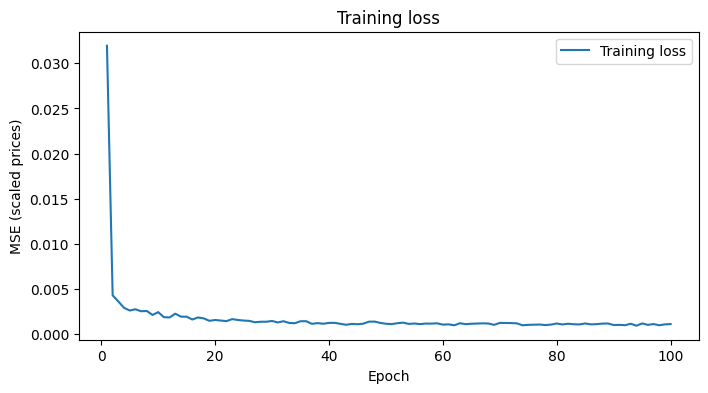

In [10]:
# Chart of the average training error per epoch. A falling curve means the model is
# learning the training data (it says nothing yet about the test period).
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(history["loss"]) + 1), history["loss"], label="Training loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled prices)")
plt.title("Training loss")
plt.legend()
plt.show()

### Step 7: Test windows (rolling one-step-ahead prediction)
The first test day (Sep 9) needs the 60 trading days before it, which are the last 60 training days, so they are joined to the test prices.
Each test day then gets its own window of the 60 actual prices before it, scaled with the training scaler.

In [11]:
# STEP 7: build one 60-day input window for each test day.
# Result: X_test with shape (23, 60, 1) and test_loader, which serves them in date order.

# To predict the first test day (Sep 9), the model needs the 60 days before it, which are
# the last 60 training days. So put those in front of the test prices.
context_prices = np.concatenate([msft_train_open[-LOOKBACK:], msft_test_open], axis=0)
# Scale with the SAME min and max as the training data (transform only, no new fit).
context_scaled = scaler.transform(context_prices).astype(np.float32)
# Window i = the 60 actual prices just before test day i. It never includes day i itself,
# so the model never sees the price it is asked to predict.
test_features = np.stack([
    context_scaled[i:i + LOOKBACK]
    for i in range(len(msft_test_open))
])
X_test = torch.from_numpy(test_features).float()
# shuffle=False keeps the windows in date order.
test_loader = DataLoader(TensorDataset(X_test), batch_size=BATCH_SIZE, shuffle=False)
print("Test inputs:", X_test.shape)  # (test days, 60 days, 1 price)

Test inputs: torch.Size([23, 60, 1])


### Step 8: Predict and compare with the baseline
`model.eval()` turns dropout off and `torch.inference_mode()` turns off gradient tracking. The predictions are converted back to dollars and
compared with the baseline "tomorrow's open = today's open" using MAE (average miss in dollars) and RMSE (like MAE, but large misses count more).

In [12]:
# STEP 8: predict every test day, convert back to dollars, and compare with the baseline.
# Result: predictions (in $), plus MAE and RMSE for the model and for the baseline.

model.eval()  # Prediction mode: dropout is switched off, so the full model is used.
prediction_batches = []
# inference_mode tells PyTorch no gradients are needed, which is faster and uses less memory.
with torch.inference_mode():
    for (batch_x,) in test_loader:
        batch_predictions = model(batch_x.to(device))
        # Move the predictions back from the GPU and turn them into a NumPy array.
        prediction_batches.append(batch_predictions.cpu().numpy())

scaled_predictions = np.concatenate(prediction_batches, axis=0)  # All test days in one array.
# Undo the 0-1 scaling to get prices in dollars.
predictions = scaler.inverse_transform(scaled_predictions)
assert predictions.shape == msft_test_open.shape  # One prediction per test day.

# Baseline: "today's opening price = yesterday's opening price". It needs no model at all,
# so the network is only useful if its error is lower than this.
baseline = context_prices[LOOKBACK - 1:-1]
# MAE = average size of the miss in $. RMSE = similar, but large misses count more.
for name, values in [("RNN", predictions), ("Previous-open baseline", baseline)]:
    errors = values - msft_test_open  # Miss on each test day (+ = too high, - = too low).
    print(f"{name}: MAE = ${np.abs(errors).mean():.2f}; RMSE = ${np.sqrt(np.mean(errors ** 2)):.2f}")

RNN: MAE = $14.60; RMSE = $16.47
Previous-open baseline: MAE = $4.96; RMSE = $6.39


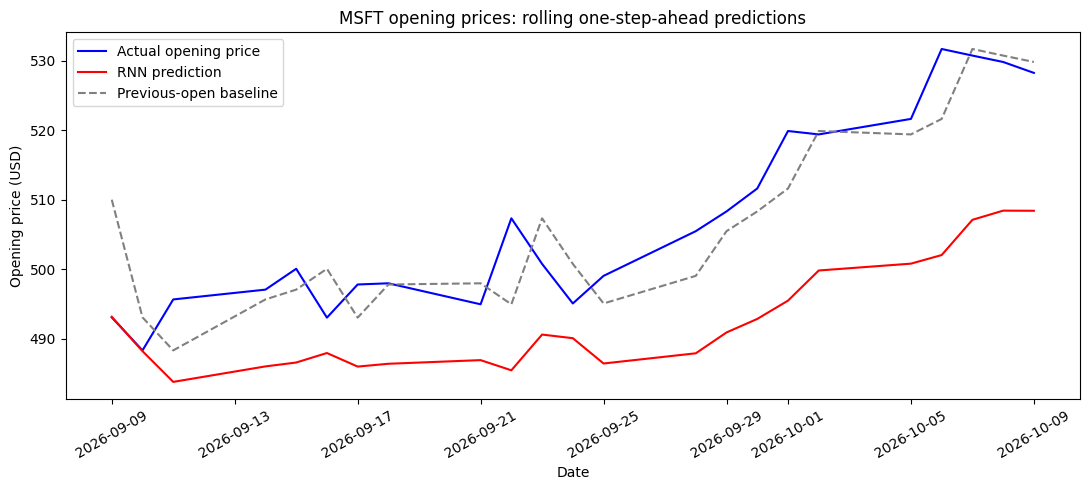

In [13]:
# Chart of the test period: actual opening prices (blue), the model's predictions (red)
# and the baseline (gray dashes).
plt.figure(figsize=(11, 5))
plt.plot(msft_test["Date"], msft_test_open[:, 0], color="blue", label="Actual opening price")
plt.plot(msft_test["Date"], predictions[:, 0], color="red", label="RNN prediction")
plt.plot(msft_test["Date"], baseline[:, 0], color="gray", linestyle="--", label="Previous-open baseline")
plt.title("MSFT opening prices: rolling one-step-ahead predictions")
plt.xlabel("Date")
plt.ylabel("Opening price (USD)")
plt.legend()
plt.xticks(rotation=30)  # Tilt the dates so they don't overlap.
plt.tight_layout()       # Fit everything inside the figure.
plt.show()

### Step 9: Save the model
`torch.save` is the PyTorch version of Keras' `model.save('...')`. The file stores the weights, the model settings, the training history and
the scaler's values. The second cell loads the file back and checks that it gives the same predictions.

In [14]:
# STEP 9: save the trained RNN to a file (PyTorch's version of Keras' model.save).
# Result: output/msft_rnn_pytorch.pt

output_dir = Path(OUTPUT_DIR).expanduser()
checkpoint_path = output_dir / "msft_rnn_pytorch.pt"
# Everything stored in the file:
checkpoint = {
    # The learned weights. A "state_dict" is PyTorch's list of every layer's weights.
    # They are copied to the CPU so the file can be opened on a computer without a GPU.
    "model_state_dict": {key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
    "model_config": model_config,      # Settings needed to rebuild the same model.
    "lookback": LOOKBACK,              # The model expects 60-day windows.
    "model_type": "vanilla_rnn_tanh",  # Label: which kind of model this is.
    "max_grad_norm": MAX_GRAD_NORM,    # Clipping limit used during training.
    "history": history,                # Training error of each epoch.
    # The scaler's learned values (training min, max, etc.). They are needed to turn
    # future predictions back into dollars with exactly the same scale.
    "scaler": {
        "feature_range": list(scaler.feature_range),
        "scale_": scaler.scale_.tolist(),
        "min_": scaler.min_.tolist(),
        "data_min_": scaler.data_min_.tolist(),
        "data_max_": scaler.data_max_.tolist(),
        "data_range_": scaler.data_range_.tolist(),
        "n_features_in_": int(scaler.n_features_in_),
        "n_samples_seen_": int(scaler.n_samples_seen_),
    },
}
output_dir.mkdir(parents=True, exist_ok=True)  # Create the output folder if it is missing.
torch.save(checkpoint, checkpoint_path)        # Write the file.
print("Saved:", checkpoint_path.resolve())

Saved: /content/output/msft_rnn_pytorch.pt


In [15]:
# Check that the saved file works: rebuild the model and the scaler from it and make sure
# they give exactly the same predictions as the model in memory.

# Read the file. weights_only=True only loads plain data (safer than loading any object).
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
# Build a new model with the same settings (it starts with random weights) ...
reloaded_model = MsftRNN(**saved["model_config"])
# ... and replace its weights with the saved ones.
reloaded_model.load_state_dict(saved["model_state_dict"])
reloaded_model = reloaded_model.to(device)
reloaded_model.eval()  # New models start in training mode, so switch dropout off.

# Rebuild the scaler by copying the saved min, max, etc. into an empty one.
reloaded_scaler = MinMaxScaler(feature_range=tuple(saved["scaler"]["feature_range"]))
for name in ("scale_", "min_", "data_min_", "data_max_", "data_range_"):
    setattr(reloaded_scaler, name, np.asarray(saved["scaler"][name], dtype=np.float32))
reloaded_scaler.n_features_in_ = saved["scaler"]["n_features_in_"]
reloaded_scaler.n_samples_seen_ = saved["scaler"]["n_samples_seen_"]

# Compare: both models get the same test windows; the outputs must match, otherwise
# assert_close stops with an error.
with torch.inference_mode():
    sample = X_test[:BATCH_SIZE].to(device)
    expected = model(sample)
    actual = reloaded_model(sample)
    torch.testing.assert_close(actual, expected)
# The rebuilt scaler must also turn the predictions into the same dollar values.
np.testing.assert_allclose(
    reloaded_scaler.inverse_transform(scaled_predictions), predictions
)
print("Reloaded model and scaler reproduce the original predictions.")

Reloaded model and scaler reproduce the original predictions.


## Part B: LSTM (class notebook `2_LSTM_apple_stock_prediction`)
Steps 1–4 of the LSTM notebook are the same code as in Part A, so the data, scaler, windows and test windows from Part A are reused.

### Reset the random state
These are the seeding lines from Step 1 and the `DataLoader` from Step 4, run again so the LSTM starts from the same random state as in its own notebook.

In [16]:
# Reset the randomness before building the LSTM (the same lines as in Steps 1 and 4).
# Training the RNN used up random numbers, so without this the LSTM would start from a
# different random state than when its class notebook is run on its own.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# A new DataLoader with a freshly seeded generator, so the batches are shuffled in the
# same order as in the class LSTM notebook.
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    num_workers=0,
)
print(f"{len(train_dataset)} examples in {len(train_loader)} batches per epoch")

2624 examples in 82 batches per epoch


### Step 5: The LSTM model
Same structure as the RNN, with `nn.LSTM` layers instead of `nn.RNN`. Each LSTM layer also keeps a cell state and uses gates to decide what to
forget, store and output (see Appendix 4.6). `nn.LSTM` returns `(outputs, (h_n, c_n))`; only the outputs are used.

In [17]:
# STEP 5 (LSTM): the same structure as the RNN in Part A, but with LSTM layers.
# An LSTM layer keeps two memories: a short-term one (the output, as in the RNN) and a
# long-term "cell state". Three gates decide what to forget, what to store and what to
# output, which helps it remember information from further back (see Appendix 4.6).

class MsftLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, dropout=0.2):
        super().__init__()  # Required first line: lets PyTorch track the layers' weights.
        # Layer 1 reads 1 value per day (the price); layers 2-4 read the 50 values per day
        # from the layer below.
        self.lstm1 = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.lstm2 = nn.LSTM(hidden_size, hidden_size, batch_first=True)
        self.lstm3 = nn.LSTM(hidden_size, hidden_size, batch_first=True)
        self.lstm4 = nn.LSTM(hidden_size, hidden_size, batch_first=True)
        # Dropout after each layer, as in the RNN (hides 20% of values during training).
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)
        self.dropout4 = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size, 1)  # 50 memory values -> 1 predicted price.

    def forward(self, x):
        # x: (B, 60, 1). An LSTM layer returns its output for every day plus a pair of final
        # memories (short-term, long-term); only the outputs are kept, the pair goes into "_".
        x, _ = self.lstm1(x)  # (B, 60, 1)  -> (B, 60, 50)
        x = self.dropout1(x)
        x, _ = self.lstm2(x)  # (B, 60, 50) -> (B, 60, 50)
        x = self.dropout2(x)
        x, _ = self.lstm3(x)  # (B, 60, 50) -> (B, 60, 50)
        x = self.dropout3(x)
        x, _ = self.lstm4(x)  # (B, 60, 50) -> (B, 60, 50)

        # Keep the output after the last day, which summarises the window: (B, 60, 50) -> (B, 50)
        x = x[:, -1, :]
        x = self.dropout4(x)
        # (B, 50) -> (B, 1): the predicted scaled price for the next day.
        return self.output(x)


model_config = {"input_size": 1, "hidden_size": HIDDEN_SIZE, "dropout": DROPOUT}  # Same as RNN.
model = MsftLSTM(**model_config).to(device)  # Build the LSTM and put it on the GPU.
print(model)
# The LSTM has about 4 times more weights than the RNN, because each gate has its own weights.
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

MsftLSTM(
  (lstm1): LSTM(1, 50, batch_first=True)
  (lstm2): LSTM(50, 50, batch_first=True)
  (lstm3): LSTM(50, 50, batch_first=True)
  (lstm4): LSTM(50, 50, batch_first=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (dropout2): Dropout(p=0.2, inplace=False)
  (dropout3): Dropout(p=0.2, inplace=False)
  (dropout4): Dropout(p=0.2, inplace=False)
  (output): Linear(in_features=50, out_features=1, bias=True)
)
Trainable parameters: 71851


### Step 6: Train the LSTM
The same training loop as in Part A, without gradient clipping (as in the class LSTM notebook).

In [18]:
# STEP 6 (LSTM): the same training loop as in Part A, except that there is no gradient
# clipping (the class LSTM notebook does not clip; LSTMs are less prone to huge gradients).

criterion = nn.MSELoss()  # Error measure: mean squared error.
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)  # Updates the weights.
history = {"loss": []}  # Average error of each epoch.

for epoch in range(EPOCHS):
    model.train()  # Training mode: dropout active.
    total_squared_error = 0.0
    examples_seen = 0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)  # Move the batch to the GPU.
        batch_y = batch_y.to(device)

        optimizer.zero_grad(set_to_none=True)  # Clear the previous batch's gradients.
        batch_predictions = model(batch_x)     # Predict one price per window.
        assert batch_predictions.shape == batch_y.shape
        loss = criterion(batch_predictions, batch_y)  # Error of this batch.
        loss.backward()   # Gradient of every weight (backpropagation through time).
        optimizer.step()  # Change the weights a small step to lower the error.

        # Add up the error of this batch, weighted by its size.
        batch_count = batch_x.size(0)
        total_squared_error += loss.item() * batch_count
        examples_seen += batch_count

    epoch_loss = total_squared_error / examples_seen  # Average error over the epoch.
    history["loss"].append(epoch_loss)
    if epoch == 0 or (epoch + 1) % 10 == 0 or epoch + 1 == EPOCHS:  # Print every 10 epochs.
        print(f"Epoch {epoch + 1:3d}/{EPOCHS}: training MSE = {epoch_loss:.6f}")

Epoch   1/100: training MSE = 0.051826
Epoch  10/100: training MSE = 0.002060
Epoch  20/100: training MSE = 0.001369
Epoch  30/100: training MSE = 0.001218
Epoch  40/100: training MSE = 0.001016
Epoch  50/100: training MSE = 0.000915
Epoch  60/100: training MSE = 0.000881
Epoch  70/100: training MSE = 0.000839
Epoch  80/100: training MSE = 0.000810
Epoch  90/100: training MSE = 0.000716
Epoch 100/100: training MSE = 0.000775


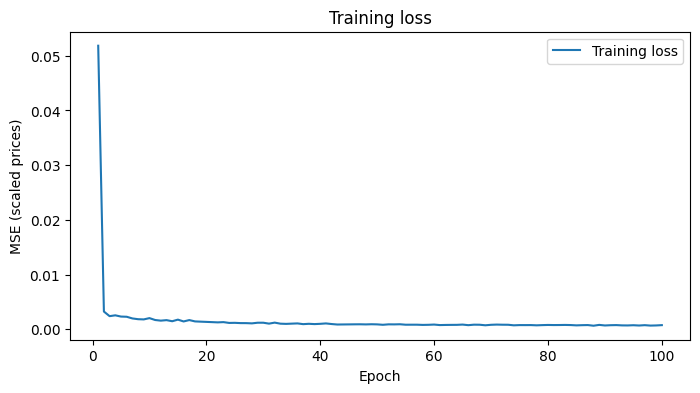

In [19]:
# Chart of the average training error per epoch. A falling curve means the model is
# learning the training data (it says nothing yet about the test period).
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(history["loss"]) + 1), history["loss"], label="Training loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled prices)")
plt.title("Training loss")
plt.legend()
plt.show()

### Step 8: Predict and compare with the baseline
The test windows from Part A (Step 7) are used.

In [20]:
# STEP 8: predict every test day, convert back to dollars, and compare with the baseline.
# Result: predictions (in $), plus MAE and RMSE for the model and for the baseline.

model.eval()  # Prediction mode: dropout is switched off, so the full model is used.
prediction_batches = []
# inference_mode tells PyTorch no gradients are needed, which is faster and uses less memory.
with torch.inference_mode():
    for (batch_x,) in test_loader:
        batch_predictions = model(batch_x.to(device))
        # Move the predictions back from the GPU and turn them into a NumPy array.
        prediction_batches.append(batch_predictions.cpu().numpy())

scaled_predictions = np.concatenate(prediction_batches, axis=0)  # All test days in one array.
# Undo the 0-1 scaling to get prices in dollars.
predictions = scaler.inverse_transform(scaled_predictions)
assert predictions.shape == msft_test_open.shape  # One prediction per test day.

# Baseline: "today's opening price = yesterday's opening price". It needs no model at all,
# so the network is only useful if its error is lower than this.
baseline = context_prices[LOOKBACK - 1:-1]
# MAE = average size of the miss in $. RMSE = similar, but large misses count more.
for name, values in [("LSTM", predictions), ("Previous-open baseline", baseline)]:
    errors = values - msft_test_open  # Miss on each test day (+ = too high, - = too low).
    print(f"{name}: MAE = ${np.abs(errors).mean():.2f}; RMSE = ${np.sqrt(np.mean(errors ** 2)):.2f}")

LSTM: MAE = $19.46; RMSE = $20.65
Previous-open baseline: MAE = $4.96; RMSE = $6.39


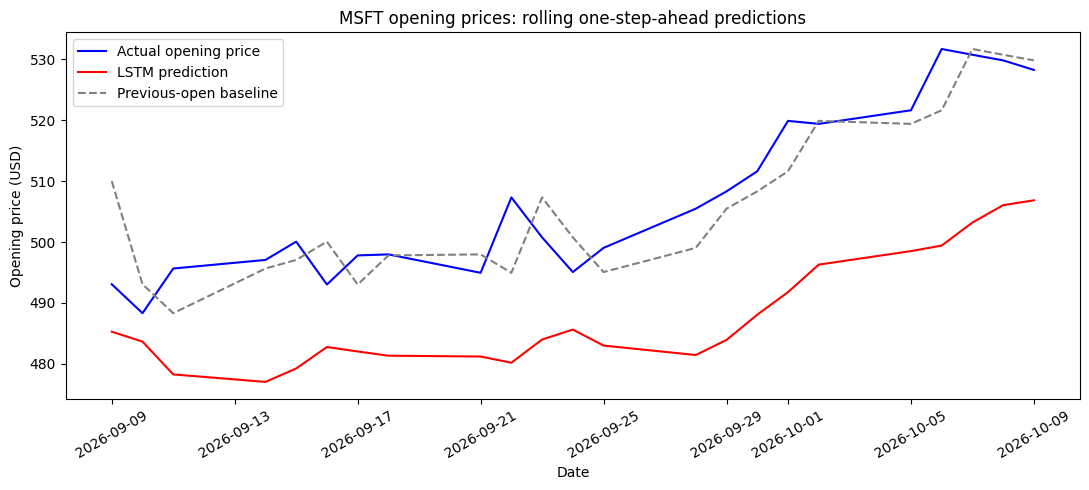

In [21]:
# Chart of the test period: actual opening prices (blue), the model's predictions (red)
# and the baseline (gray dashes).
plt.figure(figsize=(11, 5))
plt.plot(msft_test["Date"], msft_test_open[:, 0], color="blue", label="Actual opening price")
plt.plot(msft_test["Date"], predictions[:, 0], color="red", label="LSTM prediction")
plt.plot(msft_test["Date"], baseline[:, 0], color="gray", linestyle="--", label="Previous-open baseline")
plt.title("MSFT opening prices: rolling one-step-ahead predictions")
plt.xlabel("Date")
plt.ylabel("Opening price (USD)")
plt.legend()
plt.xticks(rotation=30)  # Tilt the dates so they don't overlap.
plt.tight_layout()       # Fit everything inside the figure.
plt.show()

### Step 9: Save the model

In [22]:
# STEP 9 (LSTM): save the trained LSTM to a file, as for the RNN.
# Result: output/msft_lstm_pytorch.pt

checkpoint_path = OUTPUT_DIR / "msft_lstm_pytorch.pt"
# Everything stored in the file:
checkpoint = {
    # The learned weights, copied to the CPU so the file opens on any computer.
    "model_state_dict": {key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
    "model_config": model_config,  # Settings needed to rebuild the same model.
    "lookback": LOOKBACK,          # The model expects 60-day windows.
    "history": history,            # Training error of each epoch.
    # The scaler's learned values (training min, max, etc.). They are needed to turn
    # future predictions back into dollars with exactly the same scale.
    "scaler": {
        "feature_range": list(scaler.feature_range),
        "scale_": scaler.scale_.tolist(),
        "min_": scaler.min_.tolist(),
        "data_min_": scaler.data_min_.tolist(),
        "data_max_": scaler.data_max_.tolist(),
        "data_range_": scaler.data_range_.tolist(),
        "n_features_in_": int(scaler.n_features_in_),
        "n_samples_seen_": int(scaler.n_samples_seen_),
    },
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # Create the output folder if it is missing.
torch.save(checkpoint, checkpoint_path)        # Write the file.
print("Saved:", checkpoint_path.resolve())

Saved: /content/output/msft_lstm_pytorch.pt


In [23]:
# Check that the saved file works: rebuild the model and the scaler from it and make sure
# they give exactly the same predictions as the model in memory.

# Read the file. weights_only=True only loads plain data (safer than loading any object).
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
# Build a new model with the same settings (it starts with random weights) ...
reloaded_model = MsftLSTM(**saved["model_config"])
# ... and replace its weights with the saved ones.
reloaded_model.load_state_dict(saved["model_state_dict"])
reloaded_model = reloaded_model.to(device)
reloaded_model.eval()  # New models start in training mode, so switch dropout off.

# Rebuild the scaler by copying the saved min, max, etc. into an empty one.
reloaded_scaler = MinMaxScaler(feature_range=tuple(saved["scaler"]["feature_range"]))
for name in ("scale_", "min_", "data_min_", "data_max_", "data_range_"):
    setattr(reloaded_scaler, name, np.asarray(saved["scaler"][name], dtype=np.float32))
reloaded_scaler.n_features_in_ = saved["scaler"]["n_features_in_"]
reloaded_scaler.n_samples_seen_ = saved["scaler"]["n_samples_seen_"]

# Compare: both models get the same test windows; the outputs must match, otherwise
# assert_close stops with an error.
with torch.inference_mode():
    sample = X_test[:BATCH_SIZE].to(device)
    expected = model(sample)
    actual = reloaded_model(sample)
    torch.testing.assert_close(actual, expected)
# The rebuilt scaler must also turn the predictions into the same dollar values.
np.testing.assert_allclose(
    reloaded_scaler.inverse_transform(scaled_predictions), predictions
)
print("Reloaded model and scaler reproduce the original predictions.")

Reloaded model and scaler reproduce the original predictions.


# 3. Results and discussion
The numbers below are from my Colab run (T4 GPU). Re-running the notebook gives slightly different numbers because GPU calculations
are not exactly repeatable.

### Results
2,684 training days (Jan 4, 2016 – Sep 4, 2026), 2,624 training windows of 60 days, and 23 test days (Sep 9 – Oct 9, 2026).

| Method | Training MSE after 100 epochs (scaled prices) | Test MAE | Test RMSE | Better than the baseline? |
|---|---|---|---|---|
| RNN (Part A) | 0.001085 | **\$14.60** | \$16.47 | No |
| LSTM (Part B) | 0.000775 | **\$19.46** | \$20.65 | No |
| Baseline (previous open) | – | **\$4.96** | \$6.39 | – |

### Discussion
1. Both models learned the training data. The training error fell from 0.032 (RNN) and 0.052 (LSTM) in the first epoch to about
   0.002 by epoch 10 and then leveled off. After 100 epochs the LSTM's training error was about 30% lower than the RNN's
   (0.000775 vs 0.001085).
2. On the test period both models predicted too low. MSFT opened at about \$493 on Sep 9 and about \$528 on Oct 9 (+7%), and in both
   charts the predicted line stays below the actual line. The RNN is almost exactly right on Sep 9 and Sep 10 and then falls behind;
   the LSTM is below the actual price from the first day (by about \$8 on Sep 9). For both models the gap is largest around Oct 6,
   at about \$30.
3. The predictions lag the actual price. The predicted lines are much smoother than the actual price, and they only start to rise
   after the price has already moved up at the end of September. My guess is that the 60-day windows still contained the lower
   summer 2026 prices (the training chart shows a dip to roughly \$360–\$400 and a jump to about \$510 just before the test period),
   which pulls the predictions down while the price is rising. The test prices (\$488–\$532) are inside the training range, which
   peaked at about \$550 in 2025, so this is not caused by prices the model had never seen.
4. The baseline was clearly better. "Tomorrow's open = today's open" missed by \$4.96 on average, about a third of the RNN's error
   and a quarter of the LSTM's. This is even though its Sep 9 guess had to use the Sep 4 open (Sep 8 is not in the data), which was
   about \$17 too high.
5. The RNN beat the LSTM on the test days (MAE \$14.60 vs \$19.46), even though the LSTM had the lower training error. In the charts
   the LSTM line sits a few dollars below the RNN line on most days. So a lower training error did not carry over to new data.
   In the class Apple example it was the other way round (LSTM \$4.00 vs RNN \$7.88, baseline \$2.34), so which model does better
   seems to depend on the stock and the period; with only 23 test days, the difference between the two is not very reliable.

### Conclusion
The class code worked on Microsoft data with small changes (downloading the data with `yfinance` and renaming Apple to MSFT).
Both networks learned the training data, and their predictions followed the general upward trend of the opening price during the
test period. But they lagged behind the price and were almost always too low, missing by \$14.60 (RNN) and \$19.46 (LSTM) on average,
which is 3 to 4 times worse than simply using yesterday's opening price. With only past opening prices as input, neither model is
useful for forecasting.

Ideas for improvement:
* predict the daily change (or % return) instead of the price level, which should help with the lag and the downward offset;
* use a shorter window, or give more weight to recent days;
* add more inputs (close, high, low, volume, a market index);
* keep the last part of the training period as a validation set for tuning and early stopping.

---
# 4. Appendix: How RNNs and LSTMs work

## 4.1 Sequences
A stock price, a sentence or a song is a sequence: the order matters, and earlier items help explain later ones. To guess tomorrow's
Microsoft opening price, you would look at the recent history, for example whether the price has been rising or falling.

* A regular (feed-forward) neural network looks at one input at a time and has no memory of earlier inputs.
* A recurrent neural network (RNN) reads a sequence one step at a time and carries a memory, called the hidden state `h`, from each
  step to the next. "Recurrent" means repeating: the same cell is used at every step, and its output is fed back in as an input at
  the next step.

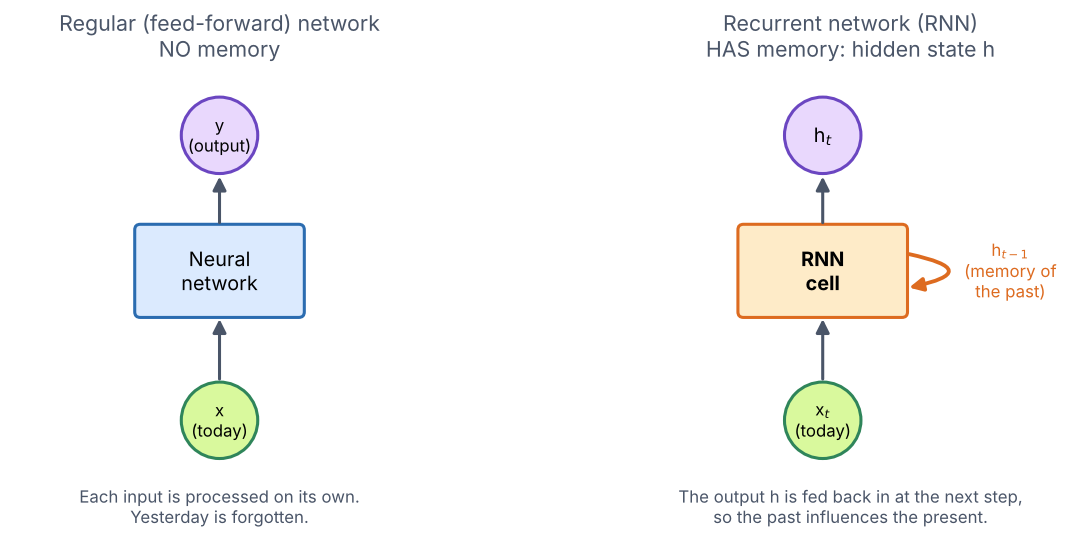

When you read "The river spread over its bank", you know "bank" means a riverside because you remember the word "river".
The hidden state plays the same role for an RNN: it is a short summary of everything read so far.

## 4.2 The RNN formula
At each step `t`, the RNN cell combines today's input $x_t$ with the previous memory $h_{t-1}$ to get the new memory $h_t$:

$$h_t = \tanh\left(w_x \cdot x_t \;+\; w_h \cdot h_{t-1} \;+\; b\right)$$

| Symbol | Meaning | In the stock example |
|---|---|---|
| $x_t$ | the input at step `t` | the (scaled) opening price on day `t` |
| $h_{t-1}$ | the memory from the previous step ($h_0 = 0$ at the start) | a summary of all earlier days |
| $w_x$ | weight on the input | how much "today" matters |
| $w_h$ | weight on the memory | how much "the past" matters |
| $b$ | bias | a constant shift |
| $\tanh$ | activation function | keeps the result between −1 and 1 |
| $h_t$ | the new memory (hidden state) | passed on to the next day; after the last day it is used for the prediction |

The same weights $w_x$, $w_h$ and $b$ are used at every step. The RNN doesn't learn separate weights for day 1, day 2 and so on;
it learns one rule for updating its memory and applies it at each step. Training is the process of finding good values for these weights.

In the real model, $x_t$ and $h_t$ are vectors ($h_t$ has 50 numbers because there are 50 units) and the weights are matrices.

## 4.3 A small worked example
Take an RNN with one memory unit that reads three days of scaled prices and predicts day 4.

* Inputs (scaled prices, going up): $x_1 = 0.2,\; x_2 = 0.5,\; x_3 = 0.9$
* Weights (assume training already found them): $w_x = 1.0,\; w_h = 0.5,\; b = 0$; output layer: $\hat{y} = 1.1 \cdot h_3$
* Starting memory: $h_0 = 0$

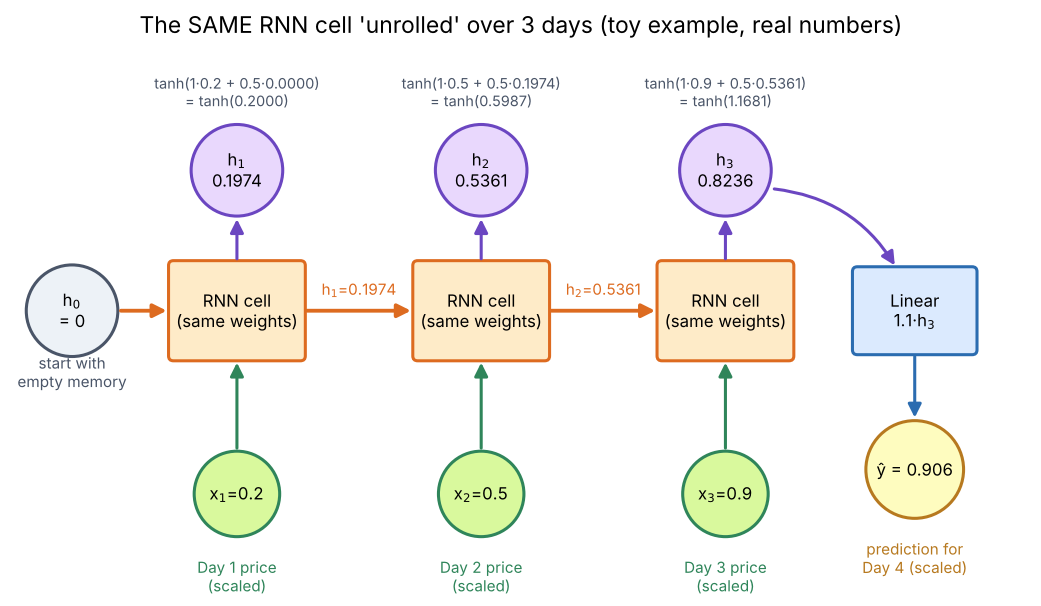

| Step | What happens | Calculation | Result |
|---|---|---|---|
| Day 1 | Read $x_1$; the memory is still empty | $h_1 = \tanh(1.0 \times 0.2 + 0.5 \times 0) = \tanh(0.2000)$ | $h_1 = 0.1974$ |
| Day 2 | Read $x_2$ and use day 1 (through $h_1$) | $h_2 = \tanh(1.0 \times 0.5 + 0.5 \times 0.1974) = \tanh(0.5987)$ | $h_2 = 0.5361$ |
| Day 3 | Read $x_3$ and use days 1–2 (through $h_2$) | $h_3 = \tanh(1.0 \times 0.9 + 0.5 \times 0.5361) = \tanh(1.1681)$ | $h_3 = 0.8236$ |
| Predict | Turn the final memory into a price | $\hat{y} = 1.1 \times 0.8236$ | $\hat{y} = 0.906$ |

$h_3$ depends on all three days: on $x_3$ directly, on $x_2$ through $h_2$, and on $x_1$ through $h_1$ and $h_2$. This chain is how
an RNN remembers earlier inputs. Drawing the loop as a row of copies, as in the figure, is called unrolling the RNN through time.
The prediction 0.906 is a bit higher than the last price (0.9), so this small network expects the upward trend to continue a little.

Inside one cell (Day 2): each input is multiplied by its weight, the results are added, and the sum goes through $\tanh$.

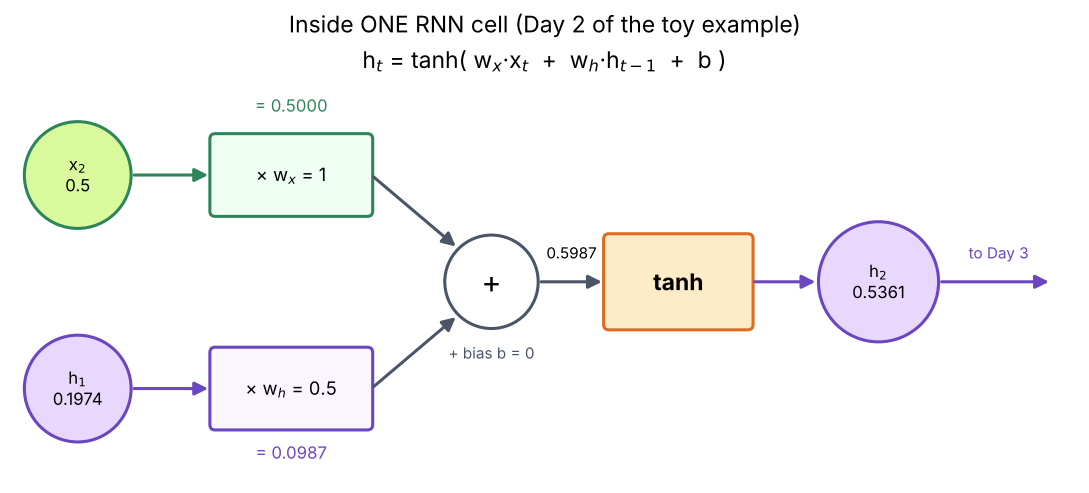

The three steps on the $\tanh$ curve. The output always stays between −1 and 1.

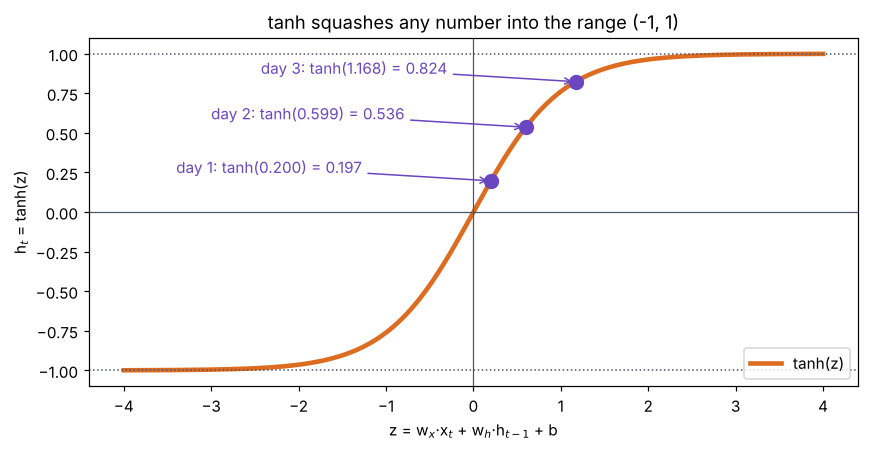

## 4.4 Checking the example in code
The cell below repeats the calculation with a simple loop and then with PyTorch's `nn.RNN` layer using the same weights. It also
shows that order matters: the same three prices in falling order give a different memory and a lower prediction.

In [24]:
import math                                   # math.tanh is used for the hand calculation.
import torch                                  # PyTorch, to compare with a real RNN layer.
from torch import nn                          # nn.RNN lives in torch.nn.

x_days = [0.2, 0.5, 0.9]                      # Three days of scaled opening prices (going up).
w_x, w_h, b, w_y = 1.0, 0.5, 0.0, 1.1         # The example weights: input, memory, bias, output.


def tiny_rnn(sequence):  # Runs the one-unit RNN over a sequence and returns its prediction for the next day.
    h = 0.0                                   # h0 = 0: start with an empty memory.
    for t, x in enumerate(sequence, start=1): # Read the sequence one day at a time (t = 1, 2, 3).
        h = math.tanh(w_x * x + w_h * h + b)  # The RNN formula: mix today's input with yesterday's memory.
        print(f"  day {t}: x = {x:.1f} -> h_{t} = {h:.4f}")  # Show the memory after each day.
    return w_y * h                            # Output layer: turn the final memory into a prediction.


print("Rising prices  [0.2, 0.5, 0.9]:")                         # First experiment: upward trend.
print(f"  prediction for day 4 = {tiny_rnn(x_days):.4f}")        # Expect 0.9060, as in the table above.
print("Falling prices [0.9, 0.5, 0.2] (same numbers, reversed):")  # Second experiment: downward trend.
print(f"  prediction for day 4 = {tiny_rnn(x_days[::-1]):.4f}")  # A different (lower) result: the RNN noticed the order.

rnn = nn.RNN(input_size=1, hidden_size=1, batch_first=True)  # A real PyTorch RNN layer: 1 input, 1 memory unit, tanh.
with torch.no_grad():                         # We are setting weights by hand, not training, so gradients are not needed.
    rnn.weight_ih_l0.fill_(w_x)               # Set the input weight to w_x = 1.0.
    rnn.weight_hh_l0.fill_(w_h)               # Set the memory weight to w_h = 0.5.
    rnn.bias_ih_l0.fill_(b)                   # PyTorch has two biases that are added together; set the first to b = 0...
    rnn.bias_hh_l0.fill_(0.0)                 # ...and the second to 0.
    seq = torch.tensor(x_days).reshape(1, 3, 1)  # Shape the prices as (batch = 1, time steps = 3, features = 1).
    outputs, h_last = rnn(seq)                # outputs holds h1, h2, h3; h_last holds h3.
print("nn.RNN hidden states:", outputs.flatten().numpy().round(4))  # Same h1, h2, h3 as the hand calculation.

Rising prices  [0.2, 0.5, 0.9]:
  day 1: x = 0.2 -> h_1 = 0.1974
  day 2: x = 0.5 -> h_2 = 0.5361
  day 3: x = 0.9 -> h_3 = 0.8236
  prediction for day 4 = 0.9060
Falling prices [0.9, 0.5, 0.2] (same numbers, reversed):
  day 1: x = 0.9 -> h_1 = 0.7163
  day 2: x = 0.5 -> h_2 = 0.6953
  day 3: x = 0.2 -> h_3 = 0.4988
  prediction for day 4 = 0.5486
nn.RNN hidden states: [0.1974 0.5361 0.8236]


## 4.5 How this connects to the stock model
*Turning a price history into examples.* The price series is cut into many overlapping windows. Each 60-day window is an input `X`,
and the price on the next day is its target `y`.

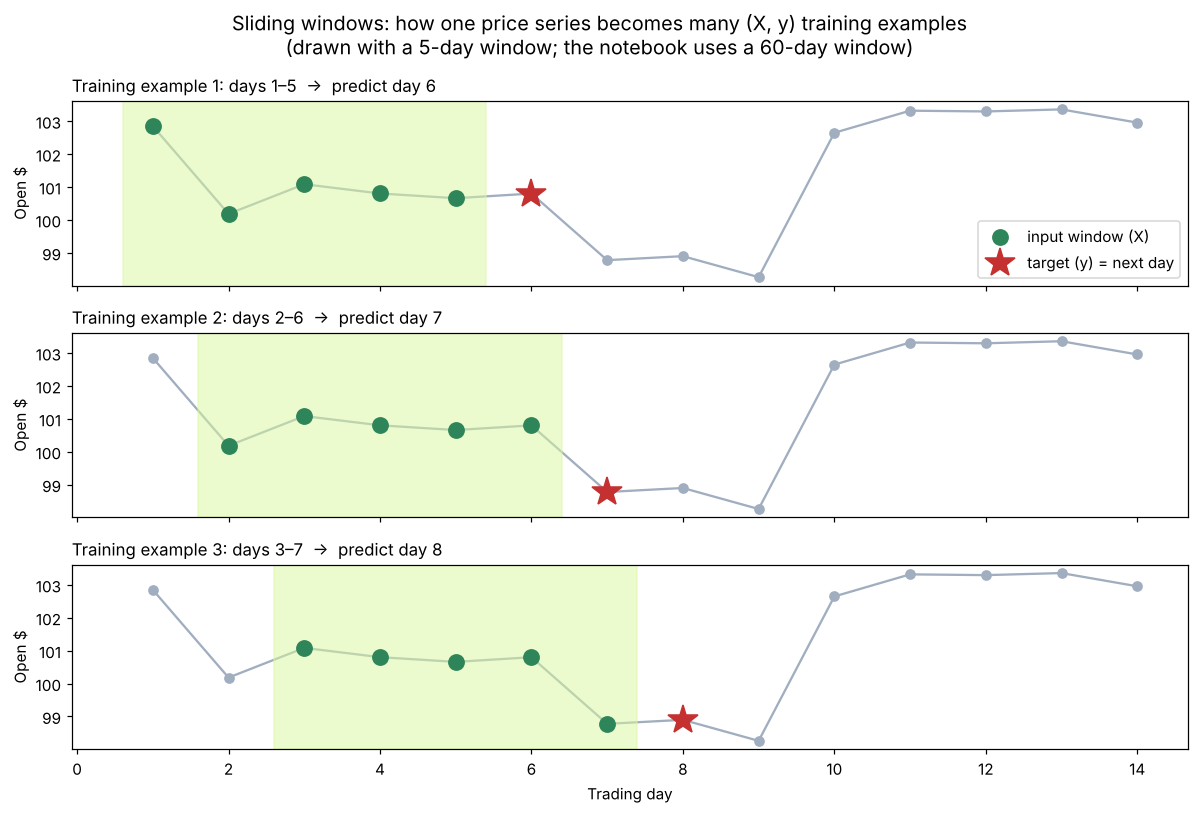

*Reading a window and making one prediction.* The network reads the 60 days one at a time, like the 3-day example. The model stacks
4 RNN layers: layer 1 reads the prices, and each higher layer reads the sequence of memories from the layer below, so it can pick up
more complex patterns. Only the final memory of the top layer (50 numbers summarizing the 60 days) goes into the linear layer, which
outputs one number: the next day's opening price. This setup, with many inputs and one output, is called many-to-one.

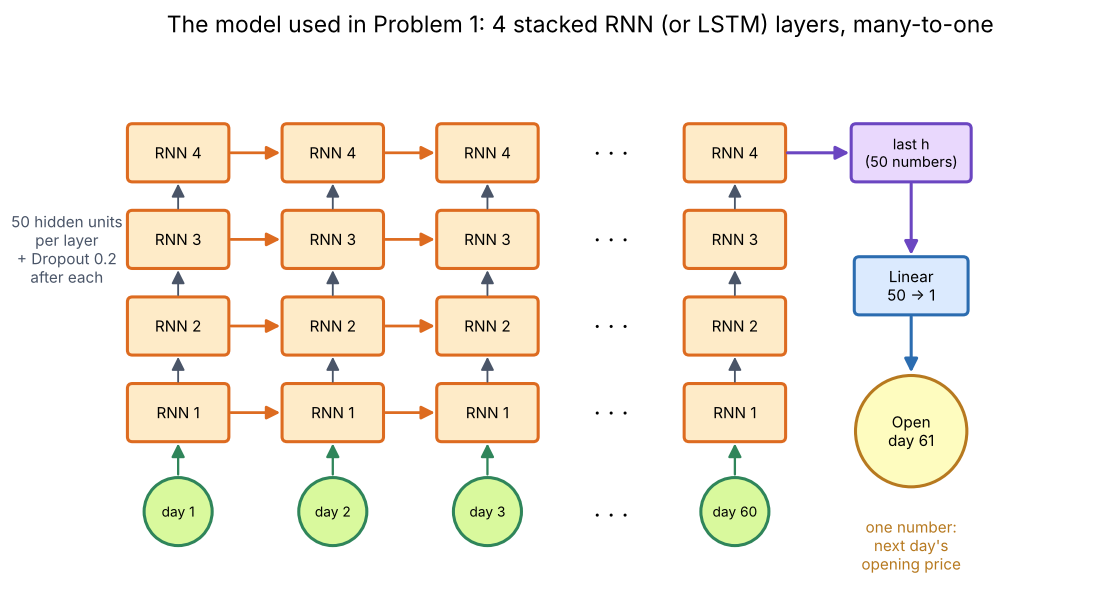

*Learning the weights.* The weights start random, so the first predictions are poor. For each batch the error (MSE) is computed, and
backpropagation through time sends it back through all 60 days to work out how each weight should change. Adam then updates the
weights. After 100 epochs the weights describe a memory-update rule that fits this stock's history.

## 4.6 Vanishing gradients and the LSTM
During backpropagation, the learning signal for an early day is multiplied by a factor at every step it travels back. If that factor
is below 1, the signal shrinks quickly. This is the vanishing gradient problem, and it means a plain RNN learns mostly from the last
few days of the window. If the factor is above 1, the signal grows instead (exploding gradients), which is why the RNN training code
clips the gradients.

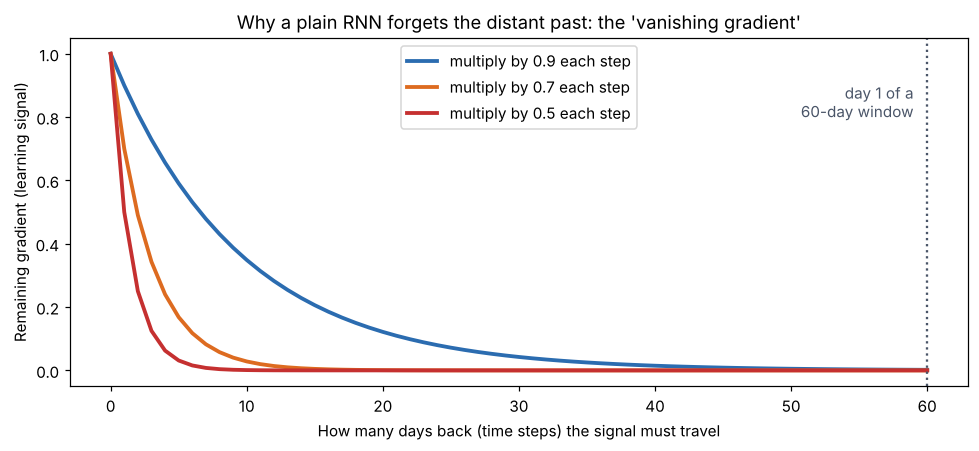

The LSTM (long short-term memory) addresses this with a second memory, the cell state, and three gates. The gates are small learned
switches with values between 0 (closed) and 1 (open). Section 4.7 goes through one LSTM cell step by step with numbers.

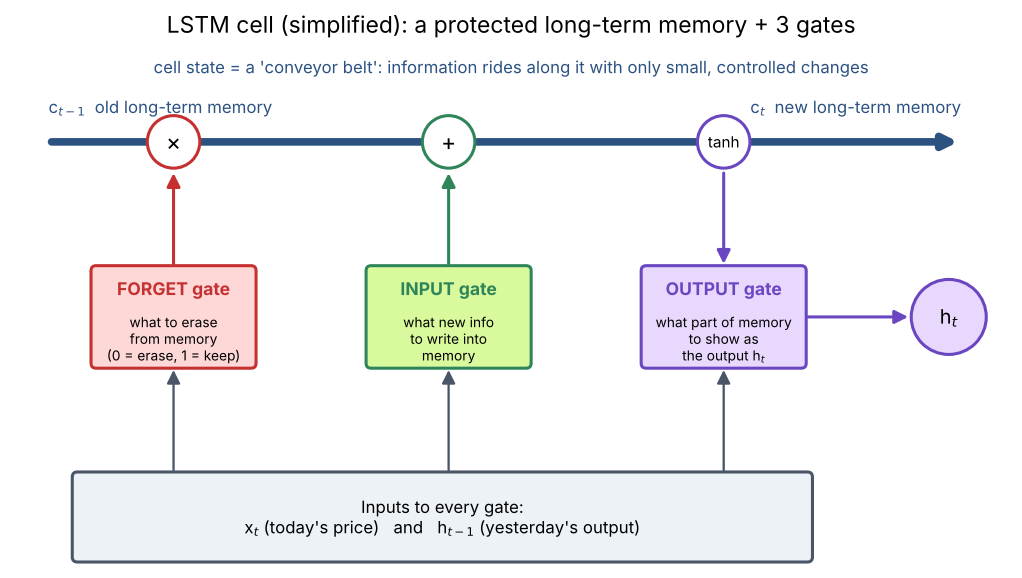

| Gate | What it decides | Stock example |
|---|---|---|
| Forget gate | Which parts of the old memory to erase | "The September dip is over, so forget it." |
| Input gate | Which parts of today's information to store | "Today's big jump is important, so remember it." |
| Output gate | Which parts of the memory to output as $h_t$ | "Pass the current trend to the next layer." |

The cell state is updated mainly by adding new information instead of repeatedly multiplying, so information and its learning signal
can last across many time steps. In Problem 1 the LSTM did reach a lower training error than the RNN
(0.000775 vs 0.001085), but it was less accurate on the 23 test days (MAE \$19.46 vs \$14.60).

## 4.7 Inside an LSTM cell, step by step
Each day `t`, an LSTM cell receives today's input $x_t$, yesterday's output $h_{t-1}$ and yesterday's long-term memory $c_{t-1}$.
It then does four small calculations and two updates. $\sigma$ is the sigmoid function: it squashes any number into the range
0 to 1, so each gate works like a dial, where 0 means "let nothing through" and 1 means "let everything through".

| # | Part | Formula | What it does |
|---|---|---|---|
| 1 | Forget gate | $f_t = \sigma(w_f x_t + u_f h_{t-1} + b_f)$ | how much of the old memory to keep (0–1) |
| 2 | Input gate | $i_t = \sigma(w_i x_t + u_i h_{t-1} + b_i)$ | how much of the new information to store (0–1) |
| 3 | Candidate | $g_t = \tanh(w_g x_t + u_g h_{t-1} + b_g)$ | the new information itself (−1 to 1) |
| 4 | Output gate | $o_t = \sigma(w_o x_t + u_o h_{t-1} + b_o)$ | how much of the memory to output (0–1) |
| 5 | New long-term memory | $c_t = f_t \cdot c_{t-1} + i_t \cdot g_t$ | keep part of the old memory and add part of the new information |
| 6 | New output | $h_t = o_t \cdot \tanh(c_t)$ | what the cell passes to the next day and to the next layer |

Each of the four parts has its own weights ($w$ for today's input, $u$ for yesterday's output, $b$ for the bias), all learned in
training. That is why the LSTM in Problem 1 has about 4 times as many weights as the RNN (71,851 vs 18,001): it has four sets of
weights where the RNN has one.

### Worked example
The same three days as the RNN example in Section 4.3 (scaled prices 0.2, 0.5, 0.9), with one memory unit and $h_0 = c_0 = 0$.
Assume training found these weights:

| Part | $w$ (today's input) | $u$ (yesterday's output) | $b$ (bias) |
|---|---|---|---|
| Forget gate $f$ | 0.5 | 0.5 | 1.0 |
| Input gate $i$ | 1.0 | 0.5 | 0 |
| Candidate $g$ | 1.0 | 1.0 | 0 |
| Output gate $o$ | 0.5 | 1.0 | 0.5 |

Day 2 in detail ($x_2 = 0.5$, and from day 1: $h_1 = 0.0698$, $c_1 = 0.1085$):
* Forget gate: $f_2 = \sigma(0.5 \times 0.5 + 0.5 \times 0.0698 + 1.0) = \sigma(1.2849) = 0.7833$, so 78% of the old memory is kept.
* Input gate: $i_2 = \sigma(1.0 \times 0.5 + 0.5 \times 0.0698) = \sigma(0.5349) = 0.6306$, so 63% of the new information is stored.
* Candidate: $g_2 = \tanh(1.0 \times 0.5 + 1.0 \times 0.0698) = \tanh(0.5698) = 0.5152$.
* Output gate: $o_2 = \sigma(0.5 \times 0.5 + 1.0 \times 0.0698 + 0.5) = \sigma(0.8198) = 0.6942$.
* New memory: $c_2 = 0.7833 \times 0.1085 + 0.6306 \times 0.5152 = 0.0850 + 0.3249 = 0.4099$.
* New output: $h_2 = 0.6942 \times \tanh(0.4099) = 0.6942 \times 0.3884 = 0.2696$.

All three days:

| Day | $x_t$ | $f_t$ | $i_t$ | $g_t$ | $o_t$ | kept $f_t c_{t-1}$ | added $i_t g_t$ | $c_t$ | $h_t$ |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.2 | 0.7503 | 0.5498 | 0.1974 | 0.6457 | 0.0000 | 0.1085 | 0.1085 | 0.0698 |
| 2 | 0.5 | 0.7833 | 0.6306 | 0.5152 | 0.6942 | 0.0850 | 0.3249 | 0.4099 | 0.2696 |
| 3 | 0.9 | 0.8299 | 0.7378 | 0.8242 | 0.7720 | 0.3402 | 0.6081 | 0.9483 | 0.5705 |

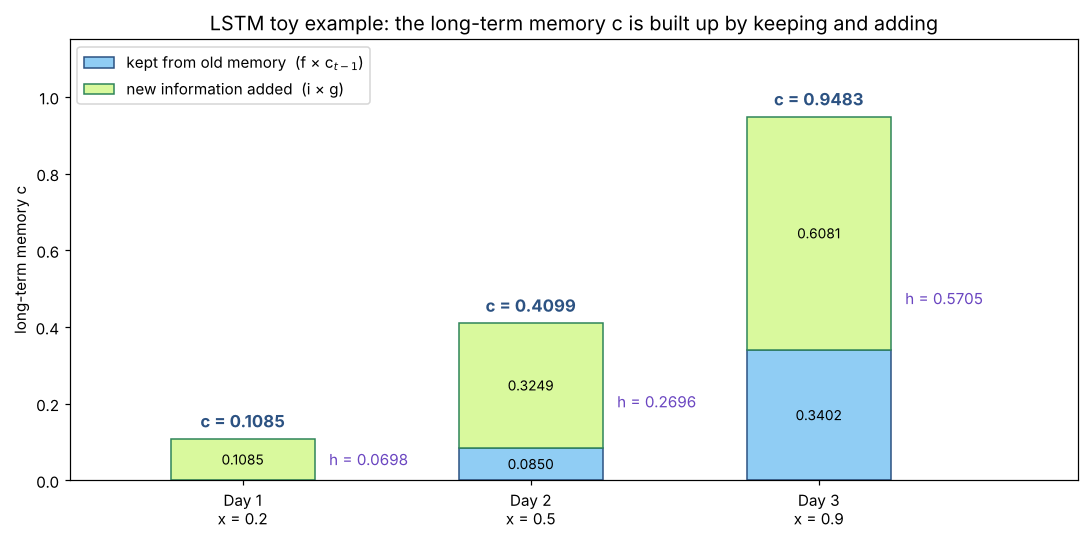

### Why this helps with long sequences
In the plain RNN, the memory is rebuilt every day by passing it through $\tanh$ together with the new input, so old information
is gradually overwritten and the learning signal shrinks at every step (Section 4.6). In the LSTM the long-term memory is carried
forward by $c_t = f_t \cdot c_{t-1} + i_t \cdot g_t$. When the forget gate is close to 1, the old memory passes through almost
unchanged: in the example, 83% of the day-2 memory is still in $c_3$ (0.3402 of 0.4099). During training the learning signal travels
back along the same path and is multiplied only by $f_t$, so the network can keep it alive over many days by keeping the forget gate open.

The cell below repeats the calculation by hand and then with PyTorch's `nn.LSTM`, using the same weights.

In [ ]:
import math                       # math.exp and math.tanh for the hand calculation.
import torch                      # PyTorch, to compare with a real LSTM layer.
from torch import nn              # nn.LSTM lives in torch.nn.


def sigmoid(z):                   # Squashes any number into the range 0-1 (used by the gates).
    return 1 / (1 + math.exp(-z))


x_days = [0.2, 0.5, 0.9]          # The same three scaled prices as in the RNN example.
# Weights of each gate: (w for today's input, u for yesterday's output, b for the bias).
weights = {"f": (0.5, 0.5, 1.0), "i": (1.0, 0.5, 0.0), "g": (1.0, 1.0, 0.0), "o": (0.5, 1.0, 0.5)}

h, c = 0.0, 0.0                   # Start with an empty output (h) and long-term memory (c).
for t, x in enumerate(x_days, start=1):  # Read the days one by one.
    # Weighted sum for each gate: w * today's input + u * yesterday's output + b.
    z = {k: w * x + u * h + b for k, (w, u, b) in weights.items()}
    f, i, o = sigmoid(z["f"]), sigmoid(z["i"]), sigmoid(z["o"])  # The three gates (0 to 1).
    g = math.tanh(z["g"])         # The new information (-1 to 1).
    c = f * c + i * g             # Keep part of the old memory and add part of the new information.
    h = o * math.tanh(c)          # Output part of the memory.
    print(f"day {t}: f={f:.4f} i={i:.4f} g={g:.4f} o={o:.4f} -> c_{t}={c:.4f}, h_{t}={h:.4f}")

# The same calculation with PyTorch's nn.LSTM (1 input value, 1 memory unit).
# PyTorch stores the four parts in the order: input gate, forget gate, candidate, output gate.
lstm = nn.LSTM(input_size=1, hidden_size=1, batch_first=True)
with torch.no_grad():             # We set the weights by hand, so no gradients are needed.
    lstm.weight_ih_l0.copy_(torch.tensor([[1.0], [0.5], [1.0], [0.5]]))  # w for i, f, g, o.
    lstm.weight_hh_l0.copy_(torch.tensor([[0.5], [0.5], [1.0], [1.0]]))  # u for i, f, g, o.
    lstm.bias_ih_l0.copy_(torch.tensor([0.0, 1.0, 0.0, 0.5]))            # b for i, f, g, o.
    lstm.bias_hh_l0.zero_()       # PyTorch has a second bias; set it to 0.
    seq = torch.tensor(x_days).reshape(1, 3, 1)  # Shape (batch = 1, days = 3, values per day = 1).
    outputs, (h_last, c_last) = lstm(seq)        # outputs = h for every day; c_last = final memory.
print("nn.LSTM outputs h:", outputs.flatten().numpy().round(4))      # Same h_1, h_2, h_3 as above.
print("nn.LSTM final memory c_3:", c_last.flatten().numpy().round(4))  # Same c_3 as above.

day 1: f=0.7503 i=0.5498 g=0.1974 o=0.6457 -> c_1=0.1085, h_1=0.0698
day 2: f=0.7833 i=0.6306 g=0.5152 o=0.6942 -> c_2=0.4099, h_2=0.2696
day 3: f=0.8299 i=0.7378 g=0.8242 o=0.7720 -> c_3=0.9483, h_3=0.5705
nn.LSTM outputs h: [0.0698 0.2696 0.5705]
nn.LSTM final memory c_3: [0.9483]
